# Lecture 7 — Class Exercise
## Part-to-Whole: Hierarchical Visualization

> **Push to:** `week07/lecture07_exercise.ipynb`


In [5]:
import pandas as pd
import plotly.express as px
import numpy as np

# Dataset: Global Energy Mix by Country and Source
df = pd.read_csv('../data/global_energy_mix.csv')

# Source type mapping — reuse from lecture
source_category = {
    'Coal': 'Fossil', 'Oil': 'Fossil', 'Natural Gas': 'Fossil',
    'Nuclear': 'Low-carbon', 'Hydro': 'Low-carbon',
    'Wind': 'Renewable', 'Solar': 'Renewable', 'Other Renewables': 'Renewable'
}
df['Source_Type'] = df['Source'].map(source_category)

print(f"Loaded: {len(df)} rows")
print(df.head(10))


Loaded: 103 rows
         Country         Region            Source  Share_pct     TWh  \
0  United States  North America              Coal         10  1015.0   
1  United States  North America               Oil         35  3220.0   
2  United States  North America       Natural Gas         34  3083.0   
3  United States  North America           Nuclear          9   798.0   
4  United States  North America             Hydro          3   339.0   
5  United States  North America              Wind          4   413.0   
6  United States  North America             Solar          3   325.0   
7  United States  North America  Other Renewables          2   229.0   
8          China           Asia              Coal         58  6929.1   
9          China           Asia               Oil         18  1620.0   

  Source_Type  
0      Fossil  
1      Fossil  
2      Fossil  
3  Low-carbon  
4  Low-carbon  
5   Renewable  
6   Renewable  
7   Renewable  
8      Fossil  
9      Fossil  


## Task 1 — Treemap: fossil fuel dependency by country

**What to build:** A treemap showing **fossil fuel TWh only**, broken down by Region → Country → Source (Coal / Oil / Natural Gas).

**Requirements:**
- Filter to fossil sources only before plotting
- Use `path=['Region', 'Country', 'Source']` for the hierarchy
- Colour encodes the fossil source type (Coal / Oil / Natural Gas) with a CVD-safe palette
- Show TWh values in labels — no percentages
- Grey out parent nodes (Region and Country level)
- Insight title naming which region or country is most fossil-dependent

> 💡 `df.loc[df['Source_Type'] == 'Fossil']`


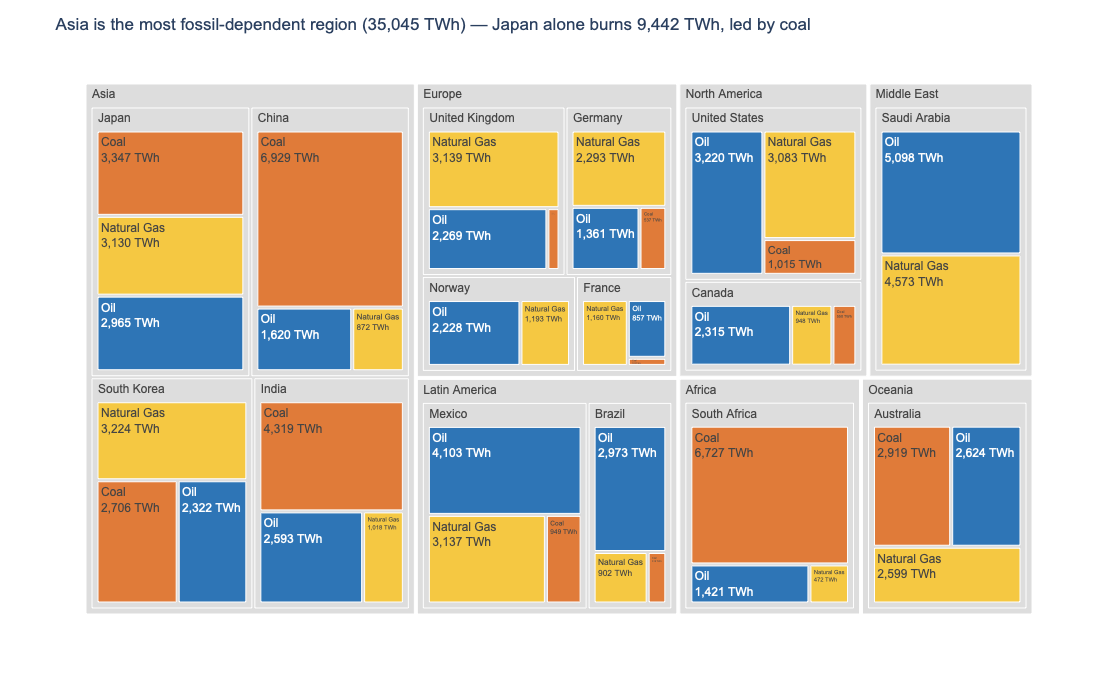

In [6]:
# Task 1 — Treemap: fossil fuel TWh by Region -> Country -> Source
df_fossil = df.loc[df['Source_Type'] == 'Fossil'].copy()

# CVD-safe course palette: blue / orange / yellow differ in hue AND lightness
fossil_colours = {
    'Coal':        '#E07B39',   # orange (accent, reused in Task 3)
    'Oil':         '#2E75B6',   # blue
    'Natural Gas': '#F5C842',   # yellow
}

fig = px.treemap(
    df_fossil,
    path=['Region', 'Country', 'Source'],
    values='TWh',                               # additive -> sums correctly at every level
    color='Source',
    color_discrete_map=fossil_colours,
    labels={'Source': 'Fossil source', 'TWh': 'Energy (TWh)'},
    height=700, width=1100,
    template='plotly_white'
)

fig.update_traces(
    textinfo='label+value',                     # TWh values, no percentages
    texttemplate='%{label}<br>%{value:,.0f} TWh',
    hovertemplate='<b>%{label}</b><br>%{value:,.0f} TWh'
)

# Grey out parent nodes (Region and Country level): keep only the three source colours
fig.data[0].marker.colors = [
    c if c in fossil_colours.values() else '#DDDDDD'
    for c in fig.data[0].marker.colors
]

# Title is built from the data
by_region = df_fossil.groupby('Region')['TWh'].sum().sort_values(ascending=False)
top_region = by_region.index[0]
top_country_row = (df_fossil.loc[df_fossil['Region'] == top_region].groupby('Country')['TWh'].sum()
                   .sort_values(ascending=False))
top_country = top_country_row.index[0]
top_source = (df_fossil.loc[df_fossil['Country'] == top_country].sort_values('TWh', ascending=False)
              .iloc[0]['Source'])

fig.update_layout(
    title=(f'{top_region} is the most fossil-dependent region ({by_region.iloc[0]:,.0f} TWh) — '
           f'{top_country} alone burns {top_country_row.iloc[0]:,.0f} TWh, led by {top_source.lower()}'),
    font=dict(family='Arial', size=12),
)
fig.show()


## Task 2 — Treemap vs bar: low-carbon energy by country

**What to build:** Build **both** a treemap and a horizontal bar chart showing total low-carbon TWh (Nuclear + Hydro) per country. Then answer the question in a markdown cell below.

**Requirements:**
- Filter to `Source_Type == 'Low-carbon'` and aggregate TWh by country
- Treemap: single-level `path=['All', 'Country']` with a dummy root node labelled `'Low-carbon'`
- Bar chart: sorted by TWh, horizontal orientation, CVD-safe colour
- Both charts show TWh values, not percentages
- Insight title on the bar chart naming the leading country

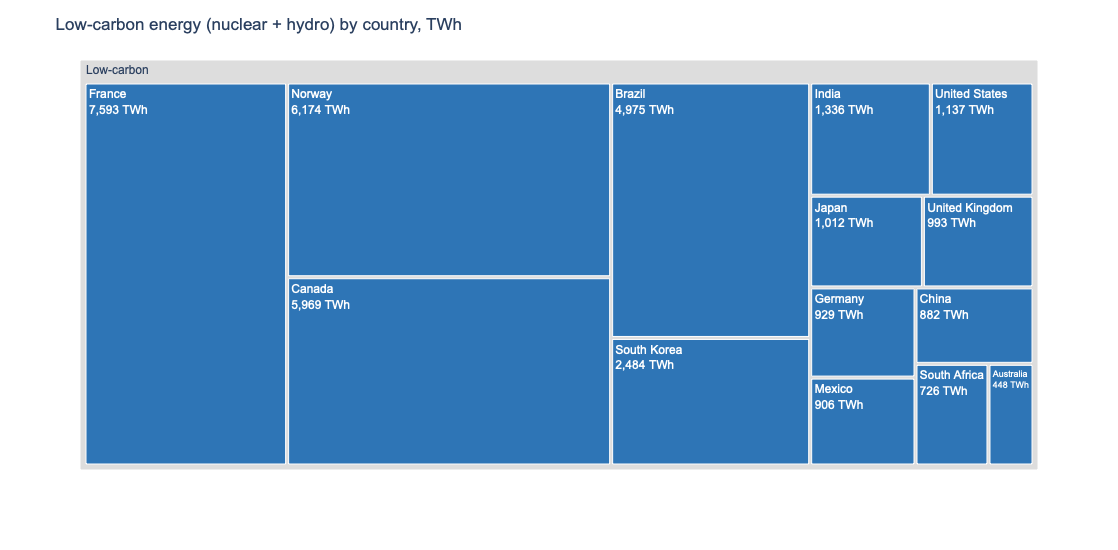

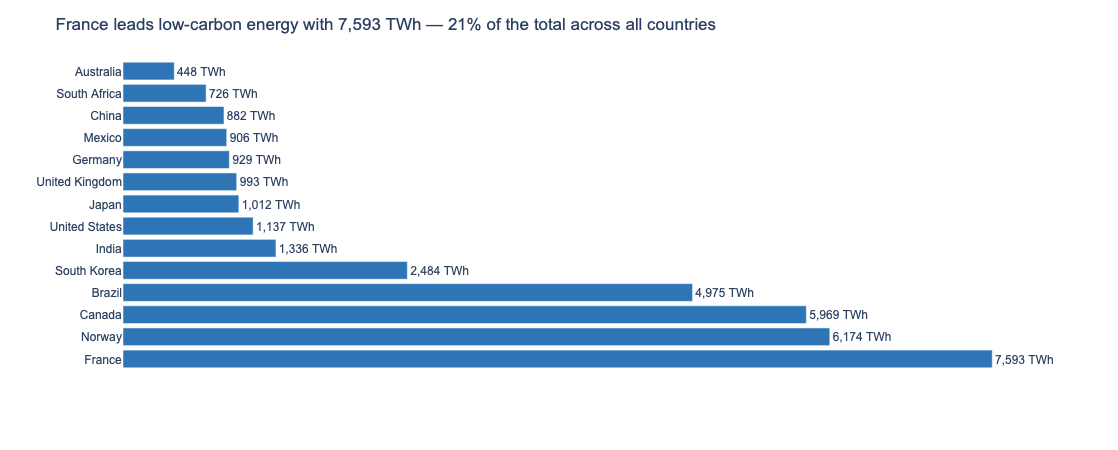

In [7]:
# Task 2 — Treemap vs horizontal bar: low-carbon (Nuclear + Hydro) TWh per country
df_low = (df.loc[df['Source_Type'] == 'Low-carbon']
            .groupby('Country', as_index=False)['TWh'].sum()
            .sort_values('TWh', ascending=False))
df_low['All'] = 'Low-carbon'                    # dummy root node
LOW_BLUE = '#2E75B6'                            # one CVD-safe colour: everything here is low-carbon

# ── Chart A: treemap (single level) ──────────────────────────────────────────
fig_tm = px.treemap(
    df_low, path=['All', 'Country'], values='TWh',
    color_discrete_sequence=[LOW_BLUE],
    labels={'TWh': 'Energy (TWh)'},
    height=550, width=1000, template='plotly_white'
)
fig_tm.update_traces(
    textinfo='label+value',
    texttemplate='%{label}<br>%{value:,.0f} TWh',
    hovertemplate='<b>%{label}</b><br>%{value:,.0f} TWh'
)
# Grey out the parent (dummy root) node, as in the lecture: keep only the palette colour
fig_tm.data[0].marker.colors = [LOW_BLUE if p != '' else '#DDDDDD' for p in fig_tm.data[0].parents]   # root has no parent
fig_tm.update_layout(
    title='Low-carbon energy (nuclear + hydro) by country, TWh',
    font=dict(family='Arial', size=12)
)
fig_tm.show()

# ── Chart B: horizontal bar, sorted ──────────────────────────────────────────
leader = df_low.iloc[0]
second = df_low.iloc[1]
fig_bar = px.bar(
    df_low, x='TWh', y='Country', orientation='h',
    text='TWh',
    category_orders={'Country': df_low['Country'].tolist()},   # largest first
    color_discrete_sequence=[LOW_BLUE],
    labels={'TWh': 'Low-carbon energy (TWh)', 'Country': ''},
    height=max(450, 32 * len(df_low)), width=1000, template='plotly_white'
)
fig_bar.update_traces(texttemplate='%{x:,.0f} TWh', textposition='outside', cliponaxis=False)
fig_bar.update_layout(
    title=f'{leader["Country"]} leads low-carbon energy with {leader["TWh"]:,.0f} TWh — {leader["TWh"] / df_low["TWh"].sum():.0%} of the total across all countries',
    font=dict(family='Arial', size=12),
    yaxis=dict(autorange='reversed', title=''),                # largest at the top
    xaxis=dict(visible=False),
    showlegend=False
)
fig_bar.show()


### Task 2 — reflection

**Which chart tells the ranking story more clearly, and why?**

- **The bar chart tells the ranking story more clearly.**
- Bars share one baseline, and length is easier to judge than area, so small differences between countries are visible.
- Sorting puts the order on the page (leader at the top), and the TWh labels give exact values.
- In the treemap, rectangles of similar size are hard to rank, and the layout does not encode order at all.
- The treemap only shows the overall size of the low-carbon "pie" and its rough split, which is not the point of this task.

## Task 3 — 100% stacked bar: which region relies most on coal?

**What to build:** A horizontal 100% stacked bar chart showing, for each **Region**, how its fossil energy splits between Coal, Oil and Natural Gas. This is the **same data as your Task 1 treemap**, visualised a second way.

**Requirements:**
- Reuse `df_fossil` from Task 1; aggregate TWh by `Region` × `Source` and convert to **shares of each region's fossil total**
- Horizontal bars, regions **sorted by coal share** (highest at the top)
- Coal is the segment on the baseline (first in `category_orders`) and the **only coloured segment** — keep it the same colour as in Task 1; Oil and Natural Gas in two greys
- Percentage labels on the coal segments only
- Insight title naming the most coal-dependent region and its coal share

> 💡 `df.groupby('Region')['TWh'].transform('sum')` gives each row its region total

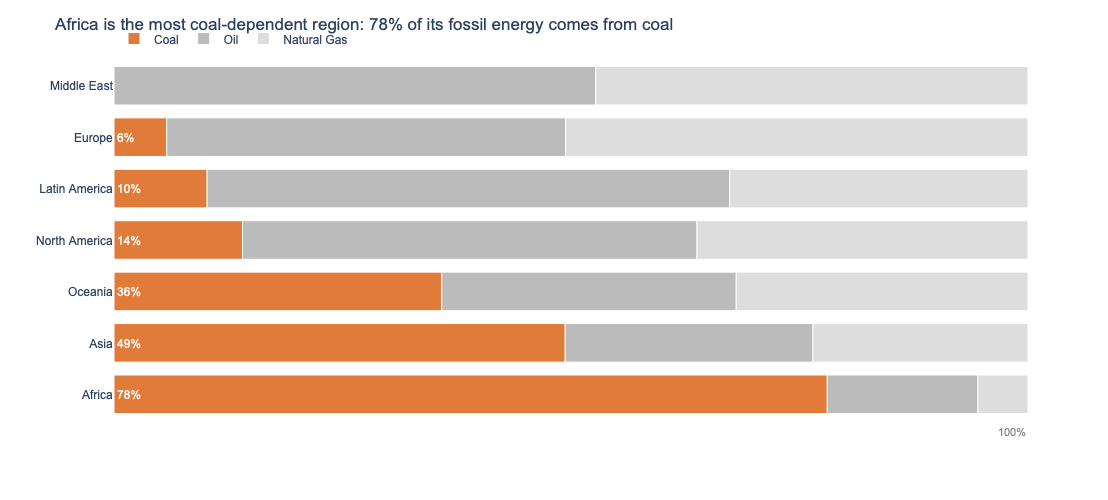

In [8]:
# Task 3 — 100% stacked horizontal bar: fossil mix by region (reuses df_fossil from Task 1)
reg = df_fossil.groupby(['Region', 'Source'], as_index=False)['TWh'].sum()
reg['Share'] = reg['TWh'] / reg.groupby('Region')['TWh'].transform('sum')   # share of each region's fossil total

# Sort regions by coal share, highest first (shown at the top)
region_order = (reg.loc[reg['Source'] == 'Coal'].sort_values('Share', ascending=False)['Region'].tolist())
# regions with no coal row would be missing -> append them
region_order += [r for r in reg['Region'].unique() if r not in region_order]

# Percentage labels on coal segments only
reg['Label'] = np.where(reg['Source'] == 'Coal', reg['Share'].map('{:.0%}'.format), '')

# Coal keeps its Task 1 orange; Oil and Natural Gas are two greys
accent = {'Coal': fossil_colours['Coal'], 'Oil': '#BBBBBB', 'Natural Gas': '#DDDDDD'}

fig = px.bar(
    reg, x='Share', y='Region', color='Source', text='Label',
    color_discrete_map=accent,
    category_orders={'Region': region_order, 'Source': ['Coal', 'Oil', 'Natural Gas']},   # coal on the baseline
    labels={'Share': 'Share of fossil energy', 'Source': 'Fossil source'},
    hover_name='Region', hover_data={'Label': False, 'Share': ':.0%'},
    height=500, width=1000, template='plotly_white'
)
fig.update_traces(
    textposition='inside', insidetextanchor='start',
    textfont=dict(color='white', size=12),
    marker_line_color='white', marker_line_width=1
)

top_r = region_order[0]
top_share = reg.loc[(reg['Region'] == top_r) & (reg['Source'] == 'Coal'), 'Share'].iloc[0]
fig.update_layout(
    title=dict(text=f'{top_r} is the most coal-dependent region: {top_share:.0%} of its fossil energy comes from coal'),
    font=dict(family='Arial', size=12),
    bargap=0.25,
    legend=dict(orientation='h', x=0, y=1.1, title=''),
    xaxis=dict(visible=False, range=[0, 1]),
    yaxis=dict(title='', autorange='reversed')                # first category (highest coal share) at the top
)
fig.add_annotation(x=1, y=0, xref='x', yref='paper', xanchor='right', yanchor='top', yshift=-4,
                   text='100%', showarrow=False, font=dict(size=11, color='grey'))
fig.show()


### Task 3 — reflection

**Your Task 1 treemap and this stacked bar show the same fossil data. Name one question each chart answers that the other cannot.**

- **Treemap only:** *Where is fossil energy concentrated in absolute terms?* Rectangle area shows that one region or country burns far more TWh than the others, and the nesting shows which countries make up each region. The 100% stacked bar hides this because every bar is scaled to the same length.
- **Stacked bar only:** *Which region relies most on coal, relative to its own fossil mix?* Bars share a baseline and are sorted by coal share, so the coal percentages can be compared directly. The treemap cannot show this, because a small region with a high coal share looks tiny.